In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
df = pd.read_csv('Zomato Restaurant Dataset.csv')
#df.shape
#df.head()
#df.info()
df.describe()
#df.isnull().sum()   


,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


### Relationship between Aggregate Rating and Online Delivery Availability

**Question:** Do restaurants that offer online delivery receive different average ratings from those that don't?

**Hypotheses**
- H0 : There is no difference in mean rating between the two groups.
- H1 : The mean ratings of the two groups differ.

**Method**
1. Removed restaurants with a rating of 0, since these are unrated rather than genuinely rated 0.
2. Grouped the remaining restaurants by online delivery availability and calculated the mean rating of each group.
3. Ran Welch's t-test to check whether the difference between the means is larger than would be expected from chance alone.

In [11]:
rated_delivery = df[df['Aggregate rating'] > 0]

summary = rated_delivery.groupby('Has Online delivery')['Aggregate rating'].agg(['mean','std','count'])
print(summary)

print(f"Avergae Gap : {summary.loc['Yes','mean'] - summary.loc['No','mean']}")

                         mean       std  count
Has Online delivery                           
No                   3.467433  0.555283   5048
Yes                  3.381274  0.540974   2355
Avergae Gap : -0.08615876124239152


t-statistic: -6.268722057892099, p-value: 3.8445121830841514e-10


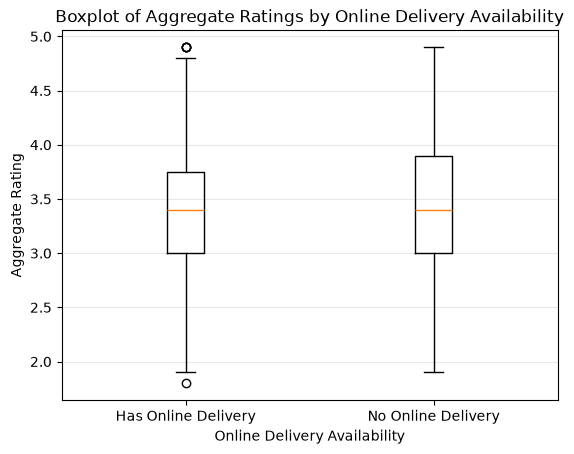

In [ ]:
a = rated_delivery[rated_delivery['Has Online delivery'] == 'Yes']['Aggregate rating']
b = rated_delivery[rated_delivery['Has Online delivery'] == 'No']['Aggregate rating']

t_val, p_val = stats.ttest_ind(a, b)
print(f"t-statistic: {t_val}, p-value: {p_val}")

fig, ax = plt.subplots()
ax.boxplot([a,b], tick_labels=['Has Online Delivery', 'No Online Delivery'])
ax.set_title('Boxplot of Aggregate Ratings by Online Delivery Availability')
ax.set_ylabel('Aggregate Rating')
ax.set_xlabel('Online Delivery Availability')
ax.grid(axis='y', alpha=0.3)

plt.show()



### **Summary of results**

| Group | Mean rating | Restaurants |
|---|---|---|
| No online delivery |   3.467433 | 5,048 |
| Online delivery |  3.381274 | 2,355 |

The difference in means is about 0.09 (delivery restaurants rate slightly lower). The t-statistic is -6.33 and the p-value is about 2.7e-10.

The t-statistic shows that the gap between the means is about 6 times larger than the standard error, in other words its much larger than the variation expected from the sampling data. The p-value shows it is very unlikely we would see a gap this large if there were truly no difference between the groups, so we reject H0.

### **Sanity Check**

Although the difference in average rating between restaurants with and without online delivery is statistically significant, it is very small: about 0.09 points on a 5-point scale, which is well under the typical variation between individual restaurants. With several thousand restaurants in the dataset, even small differences become detectable, so statistical significance alone does not mean the difference is practically important.

The result was also logically unexpected: restaurants *with* online delivery have a slightly *lower* mean rating. This test only shows an association, not the root cause. Other factors, such as country, city or price range, may influence both delivery availability and ratings, and would need to be controlled for before drawing any conclusion about delivery itself.